# Olist — исследование исходных данных

Первый этап конвейера: что лежит в девяти исходных CSV-файлах, насколько данные полные и согласованные
и какие проблемы нужно решить до построения аналитики.

**Данные:** сырые файлы `data/raw/olist/` (Kaggle, Brazilian E-Commerce Public Dataset by Olist).
Файлы читаются в pandas с явными типами: почтовые индексы — строками, даты — датами.

Итоговый перечень проблем и решений — в [словаре данных](../../../docs/data_dictionary/olist.md),
полная автоматическая статистика — в [отчёте профилирования](../../../docs/data_dictionary/olist_profile.md).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

In [2]:
from src.exploration.profile_olist import load_tables
from src.utils.config import OLIST_TABLES, RAW_DIR

tables = load_tables()
{name: df.shape for name, df in tables.items()}

{'customers': (99441, 5),
 'orders': (99441, 8),
 'order_items': (112650, 7),
 'products': (32951, 9),
 'sellers': (3095, 4),
 'payments': (103886, 5),
 'reviews': (99224, 7),
 'geolocation': (1000163, 5),
 'category_translation': (71, 2)}

## Состав данных

**Вопрос:** какие таблицы есть, насколько они большие и что описывает одна строка каждой из них?

In [3]:
overview = pd.DataFrame([{
    "таблица": name,
    "файл": OLIST_TABLES[name]["file"],
    "строк": len(df),
    "колонок": df.shape[1],
    "размер файла, МБ": (RAW_DIR / "olist" / OLIST_TABLES[name]["file"]).stat().st_size / 1e6,
} for name, df in tables.items()]).sort_values("строк", ascending=False)
overview

,таблица,файл,строк,колонок,"размер файла, МБ"
7,geolocation,olist_geolocation_dataset.csv,1000163,5,"61,27"
2,order_items,olist_order_items_dataset.csv,112650,7,"15,44"
5,payments,olist_order_payments_dataset.csv,103886,5,"5,78"
0,customers,olist_customers_dataset.csv,99441,5,"9,03"
1,orders,olist_orders_dataset.csv,99441,8,"17,65"
6,reviews,olist_order_reviews_dataset.csv,99224,7,"14,45"
3,products,olist_products_dataset.csv,32951,9,"2,38"
4,sellers,olist_sellers_dataset.csv,3095,4,"0,17"
8,category_translation,product_category_name_translation.csv,71,2,"0,00"


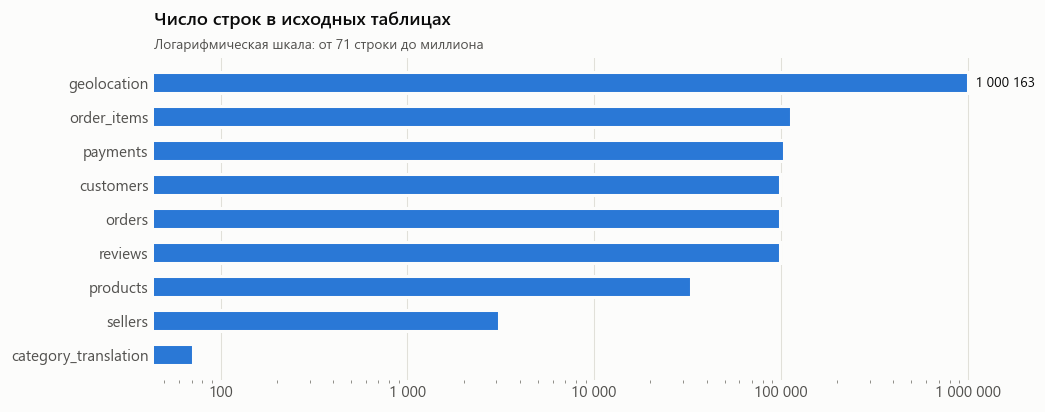

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
st.hbar(ax, overview["таблица"], overview["строк"], fmt=st.num)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: st.num(v)))
st.titles(ax, "Число строк в исходных таблицах", "Логарифмическая шкала: от 71 строки до миллиона")
st.save(fig, "olist_raw_01_table_sizes")
plt.show()

**Формула**

$$\text{строк на заказ}_T = \frac{|T|}{|\text{orders}|}$$

где $|T|$ — число строк таблицы $T$. Отношение больше 1 означает, что на один заказ приходится несколько строк.

**Пример расчёта**

$$\frac{112\,650}{99\,441} \approx 1{,}13 \;(\text{order\_items}), \qquad \frac{103\,886}{99\,441} \approx 1{,}04 \;(\text{payments}), \qquad \frac{1\,000\,163}{99\,441} \approx 10{,}1 \;(\text{geolocation})$$

**Вывод.**
- 9 таблиц, 1,55 млн строк, 126 МБ. Почти половина объёма и две трети строк — справочник геолокации (61 МБ, 1 000 163 строки),
  хотя для анализа нужна только одна точка на почтовый индекс.
- Транзакционное ядро — заказы (99 441), товарные позиции (112 650), платежи (103 886) и отзывы (99 224).
  Строк в них почти поровну, но гранулярность разная: на заказ приходится 1,13 позиции и 1,04 платежа.

## Пропуски

**Вопрос:** где в данных пропущены значения и случайны ли эти пропуски?

In [5]:
nulls = pd.DataFrame([
    {"колонка": f"{name}.{col}", "пропусков": int(df[col].isna().sum()), "доля": df[col].isna().mean()}
    for name, df in tables.items() for col in df.columns if df[col].isna().any()
]).sort_values("доля", ascending=False)
st.as_pct(nulls, ["доля"], 2)

,колонка,пропусков,доля
11,reviews.review_comment_title,87656,"88,34%"
12,reviews.review_comment_message,58247,"58,70%"
2,orders.order_delivered_customer_date,2965,"2,98%"
4,products.product_name_lenght,610,"1,85%"
3,products.product_category_name,610,"1,85%"
5,products.product_description_lenght,610,"1,85%"
6,products.product_photos_qty,610,"1,85%"
1,orders.order_delivered_carrier_date,1783,"1,79%"
0,orders.order_approved_at,160,"0,16%"
8,products.product_length_cm,2,"0,01%"


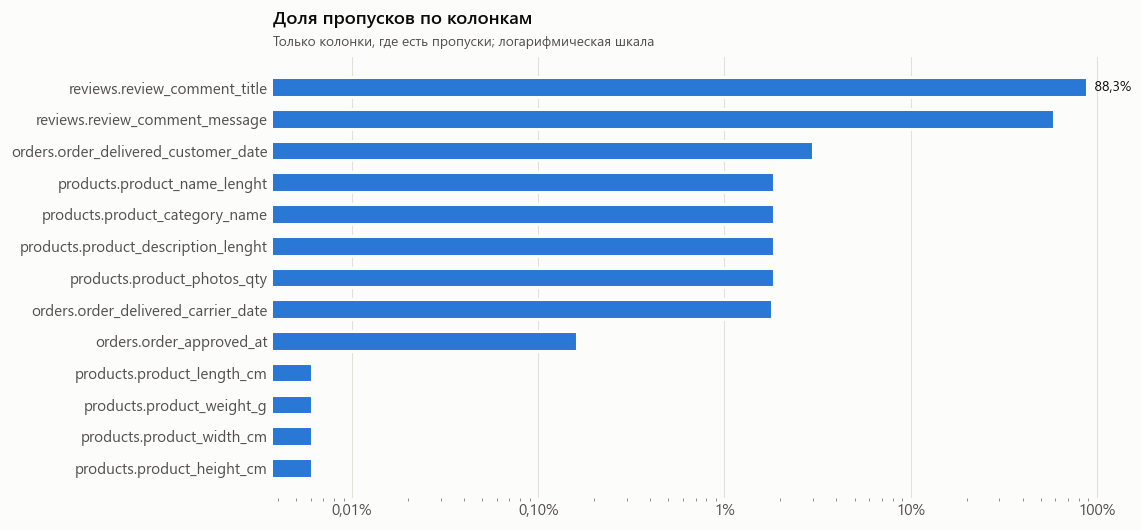

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.2))
st.hbar(ax, nulls["колонка"], nulls["доля"], fmt=lambda v: st.pct(v, 1))
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: st.pct(v, 2 if v < 0.01 else 0)))
st.titles(ax, "Доля пропусков по колонкам", "Только колонки, где есть пропуски; логарифмическая шкала")
st.save(fig, "olist_raw_02_nulls")
plt.show()

In [7]:
orders = tables["orders"]
date_cols = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
nulls_by_status = orders.groupby("order_status")[date_cols].apply(lambda g: g.isna().mean())
nulls_by_status = nulls_by_status.apply(lambda col: col.map(lambda v: st.pct(v, 0)))
nulls_by_status.insert(0, "заказов", orders.order_status.value_counts())
nulls_by_status.sort_values("заказов", ascending=False)

,заказов,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,,
delivered,96478,0%,0%,0%
shipped,1107,0%,0%,100%
canceled,625,23%,88%,99%
unavailable,609,0%,100%,100%
invoiced,314,0%,100%,100%
processing,301,0%,100%,100%
created,5,100%,100%,100%
approved,2,0%,100%,100%


**Формула**

$$\text{доля пропусков}_{c} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\, x_{i,c} = \text{NULL} \,\right]$$

где $n$ — число строк таблицы, $x_{i,c}$ — значение колонки $c$ в строке $i$.

**Пример расчёта** (дата доставки покупателю)

$$\frac{2\,965}{99\,441} \approx 0{,}0298 \;(2{,}98\%)$$

**Вывод.**
- Больше всего пропусков в тексте отзывов: заголовок пуст в 88%, комментарий — в 59%. Это не ошибка:
  покупатель может поставить оценку без текста.
- Пропуски дат заказа **не случайны**: они соответствуют статусу. У отменённых и недоступных заказов нет даты
  доставки, у `shipped` — есть передача перевозчику, но нет доставки. Пропуск здесь — информация о статусе.
- У 610 товаров (1,85%) нет категории и описания; у 2 товаров нет габаритов.

## Дубликаты и первичные ключи

**Вопрос:** уникальны ли ключи, на которых будут строиться соединения?

In [8]:
pk_rows = []
for name, meta in OLIST_TABLES.items():
    df, pk = tables[name], meta["pk"]
    pk_rows.append({
        "таблица": name,
        "ключ": ", ".join(pk) or "—",
        "дубликатов ключа": str(int(df.duplicated(subset=pk).sum())) if pk else "—",
        "полных дубликатов строк": int(df.duplicated().sum()),
        "доля полных дубликатов": df.duplicated().mean(),
    })
st.as_pct(pd.DataFrame(pk_rows), ["доля полных дубликатов"], 1)

,таблица,ключ,дубликатов ключа,полных дубликатов строк,доля полных дубликатов
0,customers,customer_id,0,0,"0,0%"
1,orders,order_id,0,0,"0,0%"
2,order_items,"order_id, order_item_id",0,0,"0,0%"
3,products,product_id,0,0,"0,0%"
4,sellers,seller_id,0,0,"0,0%"
5,payments,"order_id, payment_sequential",0,0,"0,0%"
6,reviews,review_id,814,0,"0,0%"
7,geolocation,—,—,261831,"26,2%"
8,category_translation,product_category_name,0,0,"0,0%"


In [9]:
reviews = tables["reviews"]
multi = reviews.groupby("review_id").order_id.nunique()
example_id = multi[multi > 1].index[0]
reviews.loc[reviews.review_id == example_id, ["review_id", "order_id", "review_score", "review_creation_date"]]

,review_id,order_id,review_score,review_creation_date
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,2018-03-07
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,2018-03-07


**Формула**

$$\text{доля дубликатов} = \frac{n - n_{\text{уник}}}{n}$$

где $n$ — число строк, $n_{\text{уник}}$ — число уникальных строк (или уникальных значений ключа).

**Пример расчёта** (геолокация, полные дубликаты)

$$\frac{1\,000\,163 - 738\,332}{1\,000\,163} = \frac{261\,831}{1\,000\,163} \approx 0{,}262$$

**Вывод.**
- Ключи 7 таблиц уникальны. Исключения:
  - `review_id` повторяется 814 раз: один отзыв бывает привязан к нескольким заказам одного чекаута.
    Настоящий ключ отзывов — пара `(review_id, order_id)`;
  - у геолокации ключа нет вовсе, а 26% строк — полные копии других строк.
- Полных дубликатов в транзакционных таблицах нет.

## Связи между таблицами

**Вопрос:** все ли внешние ключи находят свою запись и сколько дочерних строк приходится на один заказ?

In [10]:
fk_rows = []
for child, meta in OLIST_TABLES.items():
    for col, (parent, parent_col) in meta["fk"].items():
        c = tables[child][col].dropna()
        fk_rows.append({
            "связь": f"{child}.{col} → {parent}",
            "строк": len(c),
            "висячих строк": int((~c.isin(tables[parent][parent_col])).sum()),
            "родителей без потомков": int((~tables[parent][parent_col].isin(c)).sum()),
            "макс. на родителя": int(c.value_counts().max()),
        })
pd.DataFrame(fk_rows)

,связь,строк,висячих строк,родителей без потомков,макс. на родителя
0,orders.customer_id → customers,99441,0,0,1
1,order_items.order_id → orders,112650,0,775,21
2,order_items.product_id → products,112650,0,0,527
3,order_items.seller_id → sellers,112650,0,0,2033
4,products.product_category_name → category_tran...,32341,13,0,3029
5,payments.order_id → orders,103886,0,1,29
6,reviews.order_id → orders,99224,0,768,3


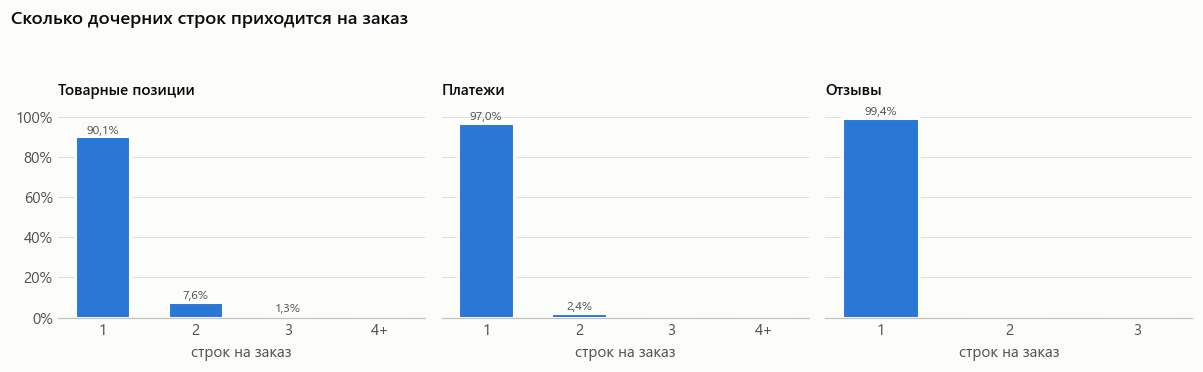

In [11]:
per_order = {
    "Товарные позиции": tables["order_items"].groupby("order_id").size(),
    "Платежи": tables["payments"].groupby("order_id").size(),
    "Отзывы": tables["reviews"].groupby("order_id").size(),
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (name, s) in zip(axes, per_order.items()):
    counts = s.clip(upper=4).value_counts().sort_index()
    share = counts / counts.sum()
    labels = [str(k) if k < 4 else "4+" for k in share.index]
    ax.bar(labels, share.values, color=st.BLUE, width=0.6, edgecolor=st.SURFACE, linewidth=2)
    ax.set_title(name, loc="left", fontsize=10, pad=8)
    ax.set_xlabel("строк на заказ")
    for x, v in zip(labels, share.values):
        if v >= 0.01:
            ax.text(x, v, st.pct(v, 1), ha="center", va="bottom", fontsize=8, color=st.INK_2)
st.percent_axis(axes[0])
fig.suptitle("Сколько дочерних строк приходится на заказ", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
st.save(fig, "olist_raw_03_rows_per_order")
plt.show()

**Формула**

$$\text{висячих} = \left|\{\, i \in \text{child} : k_i \notin K_{\text{parent}} \,\}\right|, \qquad \bar{m} = \frac{|\text{child}|}{\left|\{\, k_i \,\}\right|}$$

где $k_i$ — значение внешнего ключа в строке $i$, $K_{\text{parent}}$ — множество ключей родительской таблицы,
$\bar{m}$ — среднее число дочерних строк на родителя, у которого они есть.

**Пример расчёта** (товарные позиции на заказ)

$$\bar{m} = \frac{112\,650}{98\,666} \approx 1{,}14, \qquad \max = 21$$

**Вывод.**
- Ссылочная целостность почти идеальна: висячих ссылок нет нигде, кроме категорий товаров —
  13 товаров ссылаются на 2 категории без перевода.
- 775 заказов без товаров, 1 без платежа, 768 без отзыва.
- Связь «один ко многим» реальна для всех трёх дочерних таблиц: у 10% заказов несколько позиций,
  у 3% — несколько платежей, у 0,6% — несколько отзывов. Поэтому их нельзя соединять в одном запросе
  без предварительной агрегации (подробнее — в ноутбуке Gold).

## Покупатель и заказ

**Вопрос:** что означает `customer_id` и можно ли по нему считать повторные покупки?

In [12]:
customers = tables["customers"]
ids_per_person = customers.groupby("customer_unique_id").customer_id.nunique()
dist = ids_per_person.clip(upper=4).value_counts().sort_index()
pd.DataFrame({
    "customer_id на человека": [str(k) if k < 4 else "4+" for k in dist.index],
    "людей": dist.values,
    "доля": [st.pct(v, 2) for v in dist.values / dist.sum()],
})

,customer_id на человека,людей,доля
0,1,93099,"96,88%"
1,2,2745,"2,86%"
2,3,203,"0,21%"
3,4+,49,"0,05%"


**Вывод.**
- `customer_id` один к одному соответствует заказу: 99 441 значение на 99 441 заказ.
  Реальный человек — `customer_unique_id`: их 96 096, у 2 997 человек больше одного `customer_id`.
- Если считать покупателей по `customer_id`, повторных покупок не будет вовсе. Поэтому покупатель во всех
  слоях дальше — `customer_unique_id`.

## Временной охват

**Вопрос:** за какой период есть данные и все ли месяцы полные?

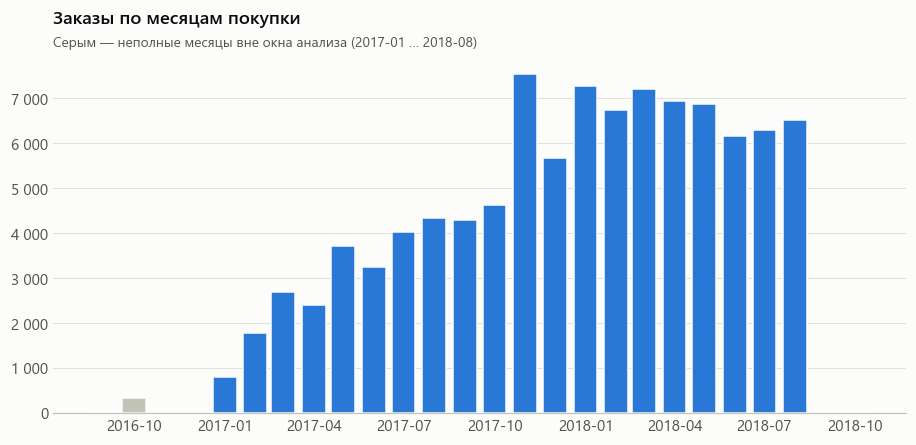

,заказов,в окне анализа
order_purchase_timestamp,,
2016-09-01,4,False
2016-10-01,324,False
2016-11-01,0,False
2016-12-01,1,False
2018-09-01,16,False
2018-10-01,4,False


In [13]:
monthly = orders.set_index("order_purchase_timestamp").resample("MS").size().rename("заказов").to_frame()
monthly["в окне анализа"] = (monthly.index >= "2017-01-01") & (monthly.index <= "2018-08-01")
fig, ax = plt.subplots()
colors = [st.BLUE if w else st.CONTEXT for w in monthly["в окне анализа"]]
ax.bar(monthly.index, monthly["заказов"], width=24, color=colors, edgecolor=st.SURFACE, linewidth=1)
st.count_axis(ax)
st.titles(ax, "Заказы по месяцам покупки", "Серым — неполные месяцы вне окна анализа (2017-01 … 2018-08)")
st.save(fig, "olist_raw_04_orders_per_month")
plt.show()
monthly.loc[~monthly["в окне анализа"]]

**Вывод.**
- Заказы идут с 4 сентября 2016 по 17 октября 2018, но первые четыре и последние два месяца почти пусты
  (ноябрь 2016 — ни одного заказа, сентябрь 2018 — 16).
- Если строить тренды по всем месяцам, получатся ложные «взлёты» и «обвалы». Окно для трендов —
  январь 2017 – август 2018.

## Согласованность дат

**Вопрос:** идут ли этапы заказа в правильном порядке и соответствуют ли даты статусам?

In [14]:
o = orders
checks = pd.Series({
    "передача перевозчику раньше покупки": (o.order_delivered_carrier_date < o.order_purchase_timestamp).sum(),
    "доставка раньше передачи перевозчику": (o.order_delivered_customer_date < o.order_delivered_carrier_date).sum(),
    "подтверждение раньше покупки": (o.order_approved_at < o.order_purchase_timestamp).sum(),
    "delivered без даты доставки": ((o.order_status == "delivered") & o.order_delivered_customer_date.isna()).sum(),
    "дата доставки без статуса delivered": ((o.order_status != "delivered") & o.order_delivered_customer_date.notna()).sum(),
}).rename("заказов").to_frame()
checks

,заказов
передача перевозчику раньше покупки,166
доставка раньше передачи перевозчику,23
подтверждение раньше покупки,0
delivered без даты доставки,8
дата доставки без статуса delivered,6


**Вывод.**
- В 166 заказах передача перевозчику записана раньше покупки, в 23 — доставка раньше передачи перевозчику.
  Вероятно, это ошибки ввода продавцов. Такие заказы нельзя использовать для расчёта сроков.
- 14 заказов со статусом, противоречащим датам. Это 0,2% заказов: на итоги не влияет,
  но такие строки помечаются флагами в Silver.

## Распределения числовых признаков

**Вопрос:** какие значения цен и стоимости доставки типичны и много ли выбросов?

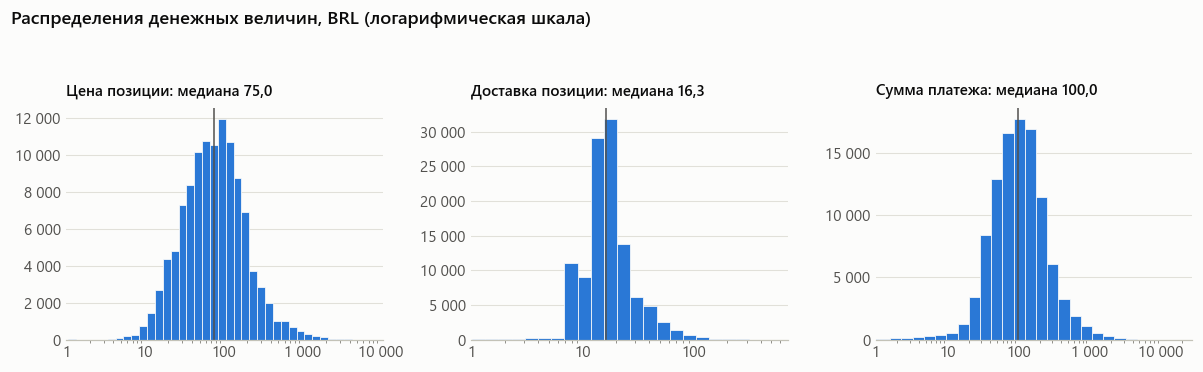

In [15]:
items, pays = tables["order_items"], tables["payments"]
series = {"Цена позиции": items.price, "Доставка позиции": items.freight_value, "Сумма платежа": pays.payment_value}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, s) in zip(axes, series.items()):
    pos = s[s > 0]
    bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 40)
    ax.hist(pos, bins=bins, color=st.BLUE, edgecolor=st.SURFACE, linewidth=0.5)
    ax.set_xscale("log")
    ax.set_xlim(left=1)
    ax.axvline(pos.median(), color=st.INK_2, linewidth=1)
    ax.set_title(f"{name}: медиана {st.num(pos.median(), 1)}", loc="left", fontsize=10, pad=8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: st.num(v)))
    st.count_axis(ax)
fig.suptitle("Распределения денежных величин, BRL (логарифмическая шкала)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
st.save(fig, "olist_raw_05_money_distributions")
plt.show()

In [16]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    return pd.Series({"Q1": q1, "Q3": q3, "верхняя граница": upper, "выбросов": int((s > upper).sum()), "доля": (s > upper).mean(), "максимум": s.max()})

outliers = pd.DataFrame({name: iqr_outliers(s) for name, s in series.items()}).T
outliers["доля"] = outliers["доля"].map(lambda v: st.pct(v, 1))
outliers["выбросов"] = outliers["выбросов"].astype(int)
outliers

,Q1,Q3,верхняя граница,выбросов,доля,максимум
Цена позиции,"39,90","134,90","277,40",8427,"7,5%","6 735,00"
Доставка позиции,"13,08","21,15","33,25",11613,"10,3%","409,68"
Сумма платежа,"56,79","171,84","344,41",7981,"7,7%","13 664,08"


**Формула** (правило межквартильного размаха)

$$\mathrm{IQR} = Q_3 - Q_1, \qquad x \text{ — выброс, если } x > Q_3 + 1{,}5\cdot\mathrm{IQR}$$

где $Q_1$ и $Q_3$ — 25-й и 75-й перцентили.

**Пример расчёта** (цена позиции)

$$Q_1 = 39{,}90, \quad Q_3 = 134{,}90, \quad \mathrm{IQR} = 95{,}00, \quad Q_3 + 1{,}5\cdot\mathrm{IQR} = 277{,}40$$

**Вывод.**
- Денежные величины распределены примерно **логнормально**: на логарифмической шкале гистограммы похожи на
  колокол. Медианная цена позиции — 74,99, медианная доставка — 16,26.
- По правилу IQR около 7–8% цен — «выбросы», но это не ошибки, а дорогие товары (до 6 735).
  Удалять их нельзя: в ноутбуке товаров видно, что дорогие редкие товары дают 13% выручки.
- Ошибочные значения единичны: 383 позиции с бесплатной доставкой и 9 нулевых платежей (ваучеры).

## Геолокация

**Вопрос:** можно ли напрямую соединять справочник геолокации с покупателями и продавцами?

In [17]:
geo = tables["geolocation"]
points = geo.groupby("geolocation_zip_code_prefix").size()
inside = geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34)
pd.DataFrame({
    "строк": [len(geo)], "почтовых индексов": [len(points)], "медиана точек на индекс": [points.median()],
    "максимум точек": [points.max()], "точек вне Бразилии": [int((~inside).sum())],
})

,строк,почтовых индексов,медиана точек на индекс,максимум точек,точек вне Бразилии
0,1000163,19015,"29,00",1146,42


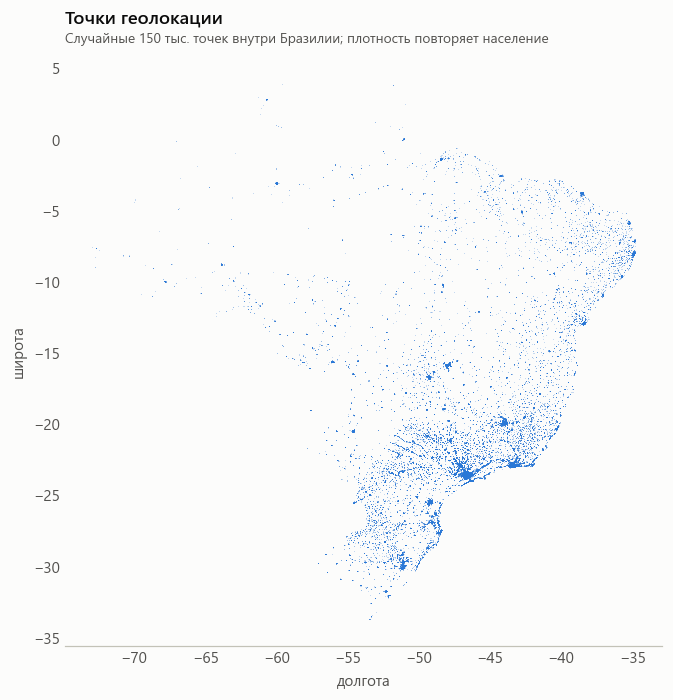

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,"28,01","-15,54",bom retiro da esperanca,SP
513631,28165,"41,61","-8,41",vila nova de campos,RJ
513643,28155,"-34,59","-58,73",santa maria,RJ
513754,28155,"42,44","13,82",santa maria,RJ
514429,28333,"38,38","-6,33",raposo,RJ


In [18]:
sample = geo[inside].sample(150_000, random_state=1)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sample.geolocation_lng, sample.geolocation_lat, s=0.3, color=st.BLUE, alpha=0.25, linewidth=0, rasterized=True)
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlabel("долгота")
ax.set_ylabel("широта")
st.titles(ax, "Точки геолокации", "Случайные 150 тыс. точек внутри Бразилии; плотность повторяет население")
st.save(fig, "olist_raw_06_geolocation_points")
plt.show()
geo.loc[~inside, ["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng", "geolocation_city", "geolocation_state"]].head()

**Вывод.**
- На один почтовый индекс приходится в среднем 53 точки (максимум — больше тысячи). Прямое соединение
  с заказами размножило бы строки в десятки раз.
- 42 точки лежат за пределами Бразилии (в Европе, Азии, океане), хотя штат у них бразильский — ошибочные координаты.
- Решение в Silver: убрать выбросы и свести справочник к одной строке на индекс (медиана координат,
  самый частый город и штат).

## Итоги

| Проблема | Масштаб | Решение |
|---|---|---|
| `customer_id` создаётся на каждый заказ | 96 096 людей на 99 441 id | покупатель = `customer_unique_id` |
| `review_id` не уникален | 814 дубликатов | ключ `(review_id, order_id)`, последний отзыв на заказ |
| геолокация без ключа и с дубликатами | 53 точки на индекс, 26% копий, 42 выброса | одна строка на индекс |
| неполные крайние месяцы | 6 месяцев | окно трендов 2017-01 … 2018-08 |
| нарушен порядок дат | 189 заказов | флаг, исключение из логистики |
| категории без перевода | 610 товаров без категории, 2 категории без перевода | `unknown` + ручной перевод |
| ведущие нули в индексах | 245 733 строки геолокации | читать индексы строкой |

Как эти решения реализованы, показано в ноутбуках Bronze и Silver.